# 04 · Exploratory analysis
Descriptive figures for Chapters 1 and 2 of the thesis (Figures 1.1–1.4, 2.1, 2.2 and 2.5). No causal estimate here. Zones are grouped into Dominion, other exposed zones (AEP, ComEd, PSEG) and the rest of PJM; group averages give every zone the same weight.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import CLEAN, RAW, save_fig

BASE_START, BASE_END = pd.Timestamp("2019-01-01"), pd.Timestamp("2021-12-01")
LATEST_START, LATEST_END = pd.Timestamp("2025-08-01"), pd.Timestamp("2026-07-01")
C = {"DOM": "#2a78d6", "Other exposed": "#eb6834", "Rest of PJM": "#1baf7a"}

zone = pd.read_parquet(CLEAN / "panel_zone_month.parquet")
hub = pd.read_parquet(CLEAN / "panel_hub_month.parquet")
cap = pd.read_csv(RAW / "manual/pjm_capacity_lda.csv")
inventory = pd.read_csv(CLEAN / "dc_unified.csv")
zone["group"] = np.where(zone.zone.eq("DOM"), "DOM", np.where(zone.zone.isin(["AEP", "COMED", "PSEG"]), "Other exposed", "Rest of PJM"))

## All-in price by group (Figure 1.1)
Energy + capacity, real 2025 $/MWh, 12-month rolling average.

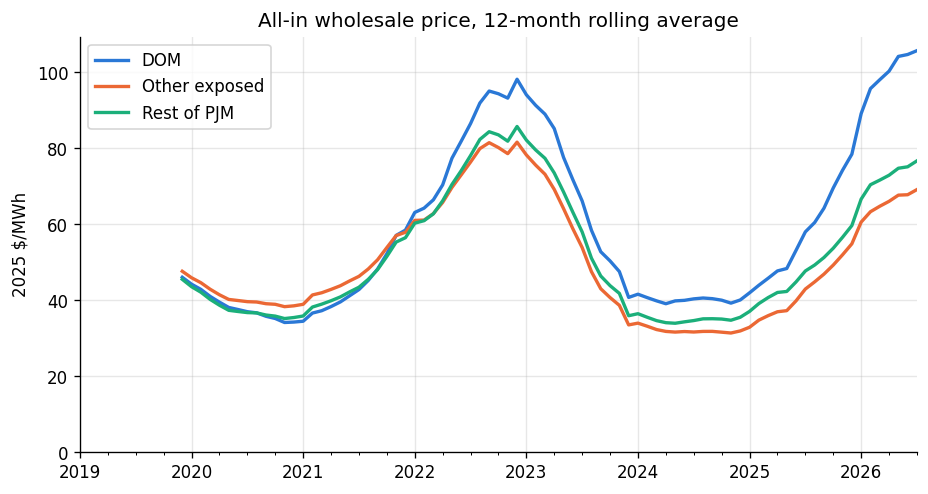

In [2]:
g = zone.groupby(['group','month']).wholesale_real.mean().unstack(0).rolling(12, min_periods=12).mean()
ax = g.plot(color=[C[c] for c in g.columns],lw=2)
ax.legend(title=None)
ax.set(title='All-in wholesale price, 12-month rolling average',ylabel='2025 $/MWh',xlabel='')
save_fig('04_wholesale_by_group')
g.to_csv(CLEAN/'wholesale_rolling.csv')

## Energy and capacity (Figure 1.2)
Yearly averages; 2026 covers January–July.

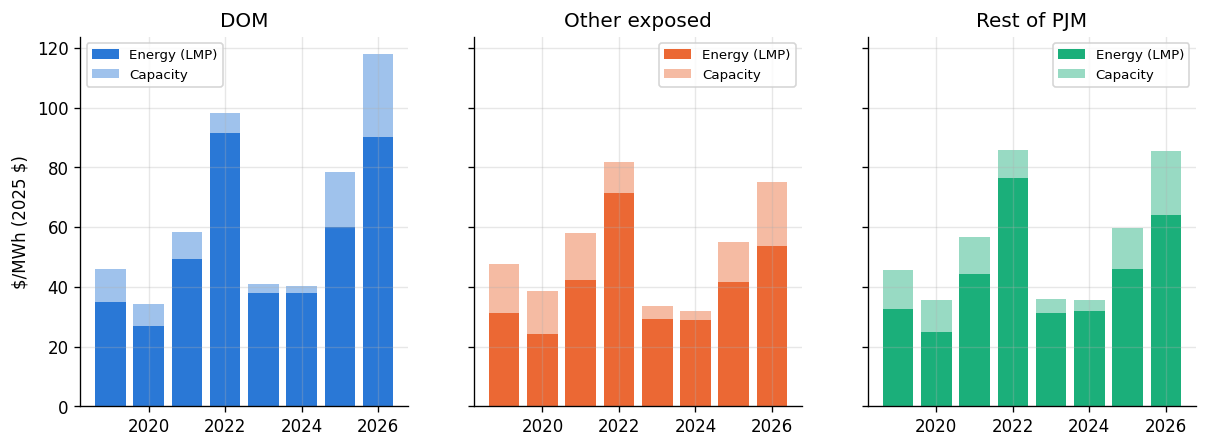

In [3]:
y = zone.assign(year=zone.month.dt.year).groupby(["group", "year"])[["lmp_real", "capacity_mwh_real"]].mean()
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, grp in zip(axes, C):
    d = y.loc[grp]
    ax.bar(d.index, d.lmp_real, color=C[grp], label="Energy (LMP)")
    ax.bar(d.index, d.capacity_mwh_real, bottom=d.lmp_real, color=C[grp], alpha=0.45, label="Capacity")
    ax.set_title(grp); ax.legend(fontsize=8)
axes[0].set_ylabel("$/MWh (2025 $)")
save_fig("04_energy_vs_capacity")

## Energy and gas prices (Figure 1.4)
The two series move together (correlation 0.9): gas is the main driver of the energy price.

Descriptive Pearson correlation: 0.9


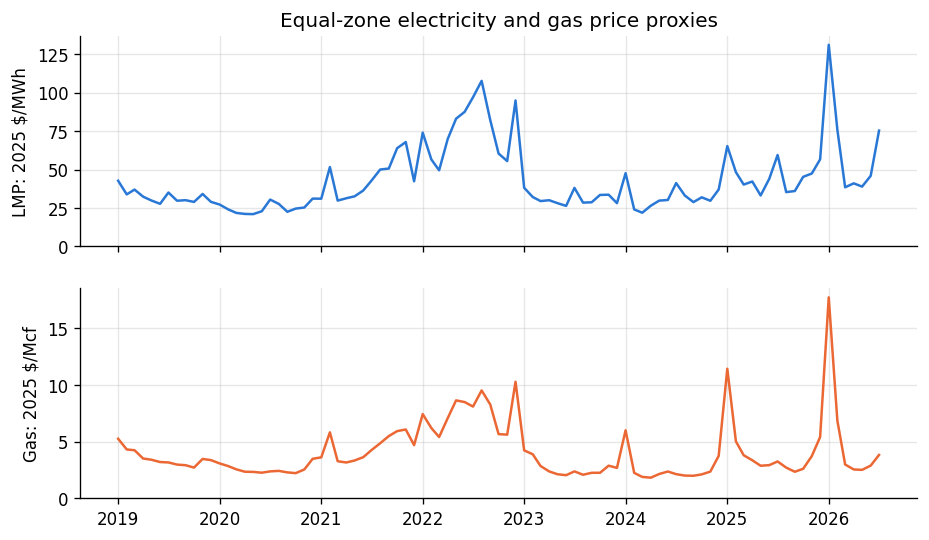

In [4]:
pjm=zone.groupby('month')[['lmp_real','gas_real']].mean()
fig,axes=plt.subplots(2,1,figsize=(9,5),sharex=True)
axes[0].plot(pjm.index,pjm.lmp_real,color=C['DOM']);axes[0].set(ylabel='LMP: 2025 $/MWh',title='Equal-zone electricity and gas price proxies')
axes[1].plot(pjm.index,pjm.gas_real,color=C['Other exposed']);axes[1].set(ylabel='Gas: 2025 $/Mcf')
save_fig('04_lmp_vs_gas')
print('Descriptive Pearson correlation:',round(pjm.corr().iloc[0,1],2))

## Data center capacity
We rebuild the operating capacity of each zone from `dc_unified.csv`, with the same rule as notebook 03, and check that it matches the panel. In July 2026 Dominion has 17,184 MW, 0.84 of its 2021 peak.

In [5]:
inv = inventory.copy()
inv["exclusion_reason"] = np.select([inv.status.ne("operating"), inv.pjm_zone.isna(), inv.operating_year.gt(LATEST_END.year)],
                                    ["not_operating", "zone_unmapped", "year_after_endpoint"], default="eligible_upstream")
base = inv[inv.exclusion_reason.eq("eligible_upstream")].copy()
base["start"] = pd.to_datetime(base.operating_year.fillna(2018).astype(int).astype(str) + "-01-01")
rebuilt = pd.DataFrame([(z, m, base.loc[base.pjm_zone.eq(z) & base.start.le(m), "facility_mw"].sum())
                        for z, m in zone[["zone", "month"]].itertuples(index=False, name=None)],
                       columns=["zone", "month", "rebuilt_mw"])
reconcile = zone[["zone", "month", "dc_mw"]].merge(rebuilt, on=["zone", "month"], validate="one_to_one")
reconcile.to_csv(CLEAN / "inventory_reconciliation.csv", index=False)
inv["screen_reason"] = inv.exclusion_reason
inv.to_csv(CLEAN / "inventory_record_ledger.csv", index=False)

exposure = reconcile.assign(screened_mw=reconcile.rebuilt_mw)
exposure.to_csv(CLEAN / "exposure_sensitivity_history.csv", index=False)

latest = exposure[exposure.month.eq(LATEST_END)].set_index("zone")
latest = latest.join(zone[zone.month.eq(LATEST_END)].set_index("zone")[["peak_2021_mw", "pjm_large_load_mw"]])
latest["screened_share_of_2021_peak"] = latest.screened_mw / latest.peak_2021_mw
latest.to_csv(CLEAN / "exposure_latest.csv")
print("Operating sites in PJM:", len(base), "| MW:", base.facility_mw.sum())
print(latest.sort_values("dc_mw", ascending=False).head(8).drop(columns="month").round(2).to_string())

Operating sites in PJM: 441 | MW: 26370.738617758452
          dc_mw  rebuilt_mw  screened_mw  peak_2021_mw  pjm_large_load_mw  screened_share_of_2021_peak
zone                                                                                                  
DOM    17184.07    17184.07     17184.07         20493             4482.0                         0.84
AEP     4896.75     4896.75      4896.75         22021             2419.0                         0.22
COMED   1811.16     1811.16      1811.16         21204                0.0                         0.09
PSEG    1227.32     1227.32      1227.32         10064               83.0                         0.12
AECO     312.95      312.95       312.95          2675                0.0                         0.12
JCPL     276.58      276.58       276.58          6128                0.0                         0.05
ATSI     250.41      250.41       250.41         12658                2.0                         0.02
DEOK      88.68     

## Data center capacity over time (Figure 2.1)
Dominion grows every January; AEP and ComEd look flat because their sites have no start year in the list.

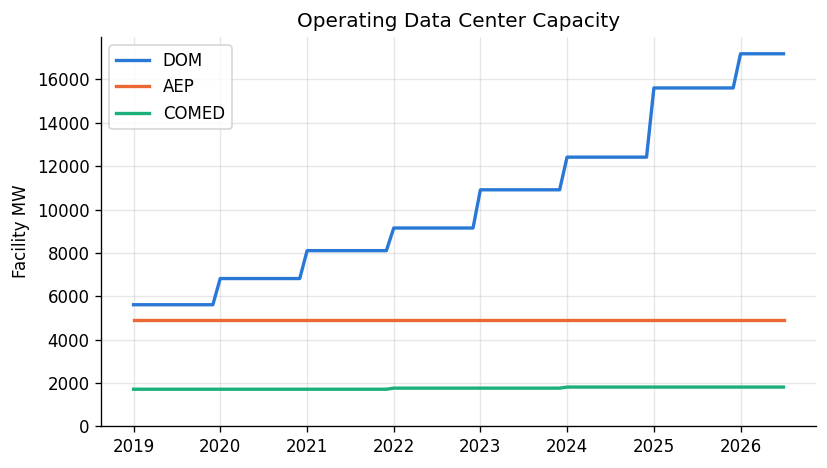

In [6]:
colors = {"DOM": "#2a78d6", "AEP": "#eb6834", "COMED": "#1baf7a"}
fig, ax = plt.subplots(figsize=(7, 4))
for z in colors:
    q = exposure[exposure.zone.eq(z)]
    ax.plot(q.month, q.screened_mw, label=z, color=colors[z], lw=2)
ax.set(title="Operating Data Center Capacity", ylabel="Facility MW")
ax.legend()
fig.tight_layout(); save_fig("04_dc_mw")

## Capacity auctions (Figure 1.3)
RTO clearing price by delivery year, nominal $/MW-day (from the PJM auction reports).

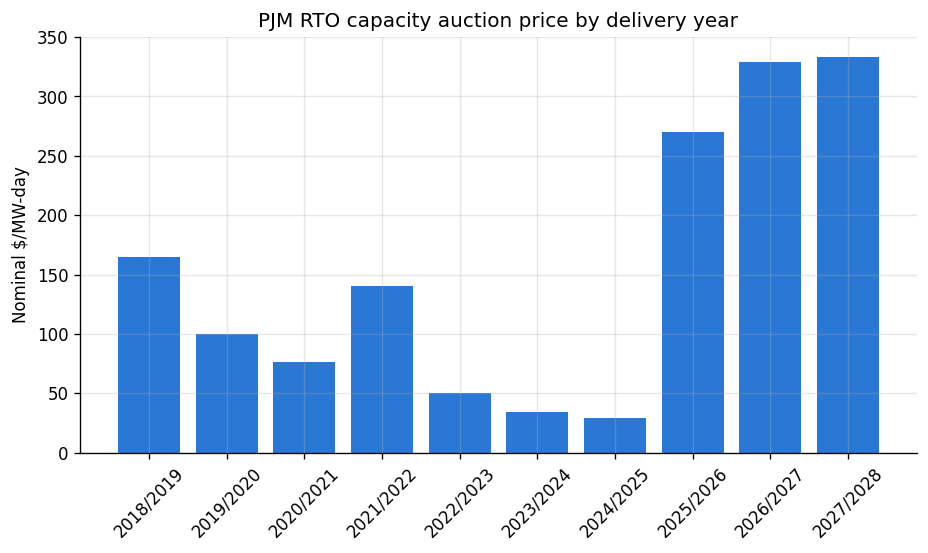

In [7]:
rto=cap[cap.lda.eq('RTO')].sort_values('delivery_year')
ax=plt.figure().gca();ax.bar(rto.delivery_year,rto.rcp_usd_mw_day,color=C['DOM'])
ax.set(title='PJM RTO capacity auction price by delivery year',ylabel='Nominal $/MW-day');ax.tick_params(axis='x',rotation=45)
save_fig('04_capacity_prices')

## Wind and solar (Figure 2.2)
Share of generation in each zone's home state, 12-month average.

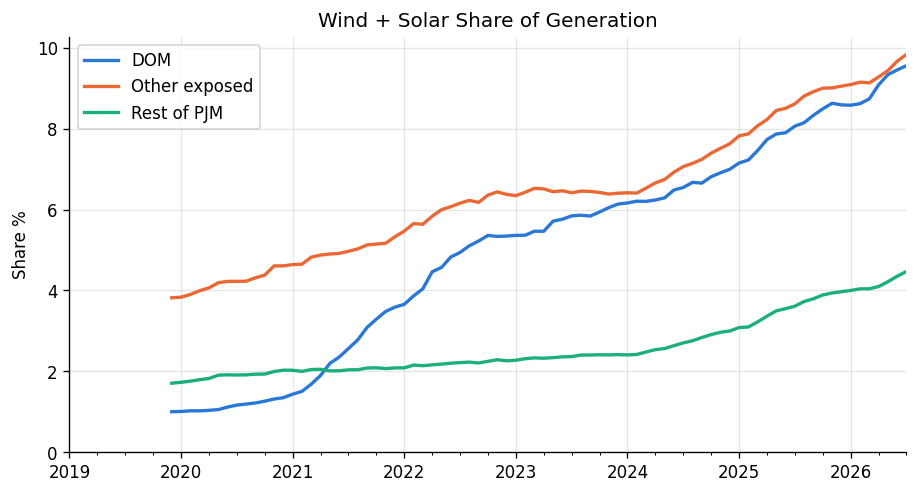

In [8]:
r=zone.groupby(['group','month']).renew_share.mean().unstack(0).rolling(12,min_periods=12).mean()*100
ax=r.plot(color=[C[c] for c in r.columns],lw=2);ax.legend(title=None)
ax.set(title='Wind + Solar Share of Generation',ylabel='Share %',xlabel='')
save_fig('04_renewables')

## Hubs (Figure 2.5)
Each hub as an index of its own 2019–21 average (= 100). Hub prices are on-peak prices.

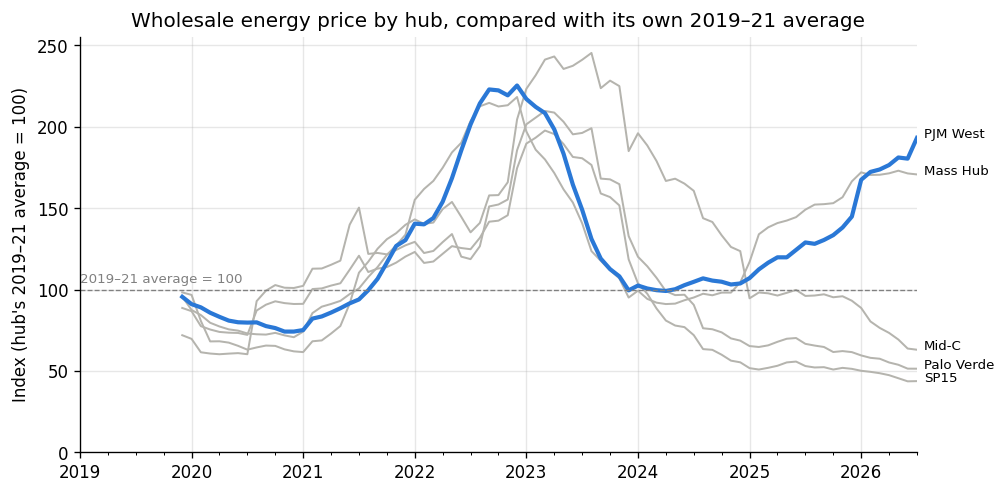

In [9]:
h=hub.pivot(index='month',columns='hub',values='price_real').sort_index()
baseline=h.loc[BASE_START:BASE_END].mean()
assert h.loc[BASE_START:BASE_END].shape[0]==36 and baseline.gt(0).all()
idx=h.div(baseline).mul(100).rolling(12,min_periods=12).mean()
ax=idx.drop(columns='PJM West').plot(color='#b5b4ae',lw=1.2,legend=False)
idx['PJM West'].plot(ax=ax,color=C['DOM'],lw=2.5)
for name in idx.columns:
    ax.annotate(name,(idx.index[-1],idx[name].iloc[-1]),xytext=(4,0),textcoords='offset points',fontsize=8)
ax.axhline(100,color='grey',lw=.8,ls='--')
ax.annotate('2019–21 average = 100',(idx.index[0],100),xytext=(0,4),textcoords='offset points',fontsize=8,color='grey')
ax.set_ylim(bottom=0)
ax.set(title="Wholesale energy price by hub, compared with its own 2019–21 average",ylabel="Index (hub's 2019–21 average = 100)",xlabel='')
save_fig('04_hubs_indexed');idx.to_csv(CLEAN/'hub_index.csv')

## Price change by group
Latest 12 months minus 2019–21. Here the rest of PJM includes BGE, Pepco and APS (+30.9 $/MWh); Table 2.3 and notebook 08 exclude them (+25.5 $/MWh).

In [10]:
per = zone.assign(p=pd.cut(zone.month, [pd.Timestamp("2018-12-01"), pd.Timestamp("2021-12-01"),
                                         pd.Timestamp("2025-07-01"), pd.Timestamp("2026-07-01")],
                           labels=["2019-21", "mid", "latest"]))
t = per[per.p != "mid"].groupby(["group", "p"], observed=True)[["lmp_real", "capacity_mwh_real", "wholesale_real"]].mean().unstack()
change = t.xs("latest", axis=1, level=1) - t.xs("2019-21", axis=1, level=1)
change.round(1).to_csv(CLEAN / "price_change_by_group.csv")
change.round(1)

,lmp_real,capacity_mwh_real,wholesale_real
group,,,
DOM,40.0,19.5,59.5
Other exposed,15.6,5.5,21.1
Rest of PJM,21.7,9.1,30.9
